In [1]:
# Parameters
ticker = "AAPL"              # Stock ticker to analyze
start_date = "2024-01-01"    # Analysis start date
end_date = "2024-12-31"      # Analysis end date
db_path = "data/data.db"     # Portable local path to the SQLite database

In [2]:
# Parameters
ticker = "PG"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


In [3]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown
import scrapbook as sb


# plotting style
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

TRADING_DAYS = 252
RF_RATE = 0.02

# 2.2 Data Loading

In [4]:
def load_stock_data(db_path: str, ticker: str, start_date: str, end_date: str) -> pd.DataFrame:
    """Load cleaned OHLC data for one ticker within a date range.    """
    if start_date > end_date:
        raise ValueError(f"start_date ({start_date}) is after end_date ({end_date})")

    query = """
        SELECT ts, ticker, open, high, low, close, adj_close, volume
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts >= ? AND ts <= ?
        ORDER BY ts
    """
    with sqlite3.connect(db_path) as conn:
        df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date))

    if df.empty:
        raise ValueError(f"No data for {ticker} in [{start_date}, {end_date}]. "
                         "Check ticker spelling, date range, and db_path.")

    df["ts"] = pd.to_datetime(df["ts"])
    df = df.sort_values("ts").reset_index(drop=True)
    return df


df = load_stock_data(db_path, ticker, start_date, end_date)

n_days = len(df)
actual_start = df["ts"].min().date()
actual_end = df["ts"].max().date()
display(Markdown(f"**{ticker} from {start_date} to {end_date}: {n_days} trading days**"))
display(Markdown(f"Actual first observation: `{actual_start}` | last observation: `{actual_end}`"))

# guard for insufficient history (20 returns need >= 21 prices)
if n_days < 21:
    display(Markdown(f"> ⚠️ **Insufficient history**: {n_days} prices < 21 required for 20 returns. "
                     "Metrics that need 20+ returns will be `N/A`."))

display(df.head())
display(df.tail())

**PG from 2024-06-01 to 2024-11-30: 126 trading days**

Actual first observation: `2024-06-03` | last observation: `2024-11-29`

,ts,ticker,open,high,low,close,adj_close,volume
0,2024-06-03,PG,163.93,166.24,163.63,164.65,162.71,5828442
1,2024-06-04,PG,164.79,167.12,164.40,167.01,165.04,6277001
2,2024-06-05,PG,167.01,167.01,164.98,166.05,164.09,5243345
3,2024-06-06,PG,165.83,168.58,165.08,168.47,166.48,6302243
4,2024-06-07,PG,168.40,168.97,166.84,167.06,165.09,4558200


,ts,ticker,open,high,low,close,adj_close,volume
121,2024-11-22,PG,174.15,177.40,173.88,176.28,176.28,10609800
122,2024-11-25,PG,177.48,178.82,176.90,177.39,177.39,19357005
123,2024-11-26,PG,177.20,179.46,177.20,179.31,179.31,6276933
124,2024-11-27,PG,180.00,180.43,178.73,179.36,179.36,5522912
125,2024-11-29,PG,178.70,179.63,178.28,179.26,179.26,3823708


# 2.3 Calculate Risk Metrics

In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns: ln(P_t / P_{t-1})."""
    prices = prices.astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        rets = np.log(prices / prices.shift(1))
    rets = rets.replace([np.inf, -np.inf], np.nan)
    return rets


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility: rolling std (ddof=1) * sqrt(252).    """
    return returns.rolling(window=window, min_periods=window).std(ddof=1) * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak.    """
    prices = prices.astype(float)
    running_peak = prices.cummax()
    drawdown = (prices - running_peak) / running_peak
    return drawdown


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio: (mean*252 - rf) / (std*sqrt(252)).    """
    r = returns.dropna()
    if len(r) < 2:
        return np.nan
    std = r.std(ddof=1)
    if not np.isfinite(std) or std == 0:
        return np.nan
    ann_mean = r.mean() * TRADING_DAYS
    ann_std = std * np.sqrt(TRADING_DAYS)
    return (ann_mean - risk_free_rate) / ann_std

In [6]:
# Use adjusted close for report returns and drawdown
prices = df["adj_close"].astype(float)

log_returns = calculate_returns(prices)
rolling_vol_20 = calculate_volatility(log_returns, window=20)
drawdown = calculate_max_drawdown(prices)

vol_threshold = rolling_vol_20.mean()      # mean rolling vol over the report window
max_dd = drawdown.min()                     # negative value
sharpe = calculate_sharpe_ratio(log_returns, risk_free_rate=RF_RATE)

display(Markdown(
    f"**Summary (calculation preview)** — Sharpe: `{sharpe:.3f}` | "
    f"Mean 20d vol: `{vol_threshold:.4f}` | Max drawdown: `{max_dd:.2%}`"
))

**Summary (calculation preview)** — Sharpe: `1.041` | Mean 20d vol: `0.1657` | Max drawdown: `-8.88%`

# 2.4 Visualization

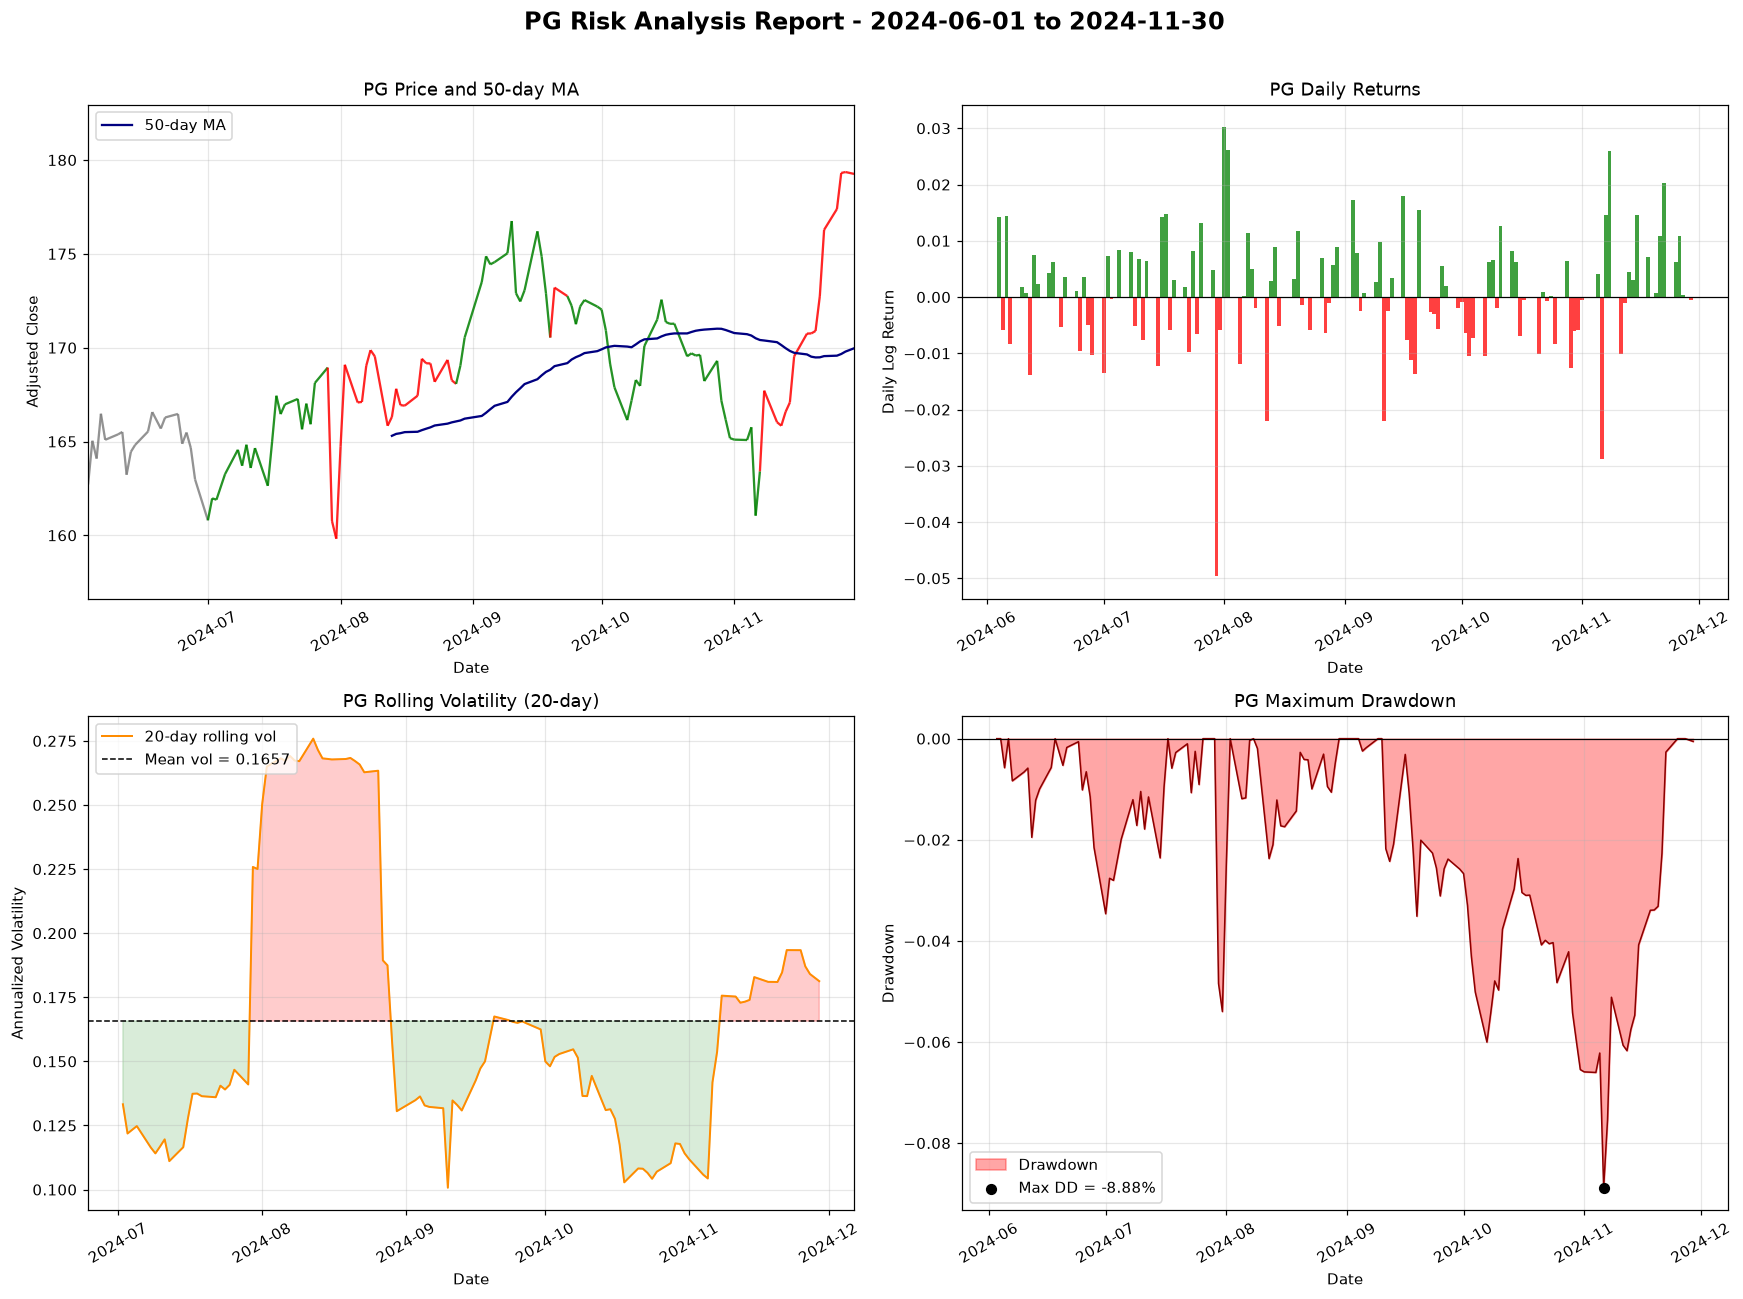

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}",
             fontsize=16, fontweight="bold")
dates = df["ts"]

# top Left: Price colored by rolling volatility
ax = axes[0, 0]
price_vals = prices.values
ma50 = prices.rolling(window=50, min_periods=50).mean()
# Build per-segment colors from rolling vol: gray = warm-up, green < mean, red > mean
vol_vals = rolling_vol_20.values
seg_colors = []
for i in range(len(dates) - 1):
    v = vol_vals[i + 1]
    if np.isnan(v):
        seg_colors.append("gray")
    elif v > vol_threshold:
        seg_colors.append("red")
    else:
        seg_colors.append("green")  # equal-to-mean is green
points = np.array([mdates.date2num(dates), price_vals]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
lc = LineCollection(segments, colors=seg_colors, linewidths=1.5, alpha=0.85)
ax.add_collection(lc)
ax.set_xlim(dates.min(), dates.max())
ax.set_ylim(np.nanmin(price_vals) * 0.98, np.nanmax(price_vals) * 1.02)
if ma50.notna().any():
    ax.plot(dates, ma50, color="navy", linewidth=1.5, label="50-day MA")
else:
    ax.text(0.5, 0.9, "50-day MA unavailable (<50 prices)",
            transform=ax.transAxes, ha="center", color="gray")
ax.set_title(f"{ticker} Price and 50-day MA")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted Close")
ax.legend(loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

# Top Right: Daily returns
ax = axes[0, 1]
valid = log_returns.notna()
bar_dates = dates[valid]
bar_rets = log_returns[valid]
colors = np.where(bar_rets >= 0, "green", "red")
ax.bar(bar_dates, bar_rets, color=colors, alpha=0.75, width=1.0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"{ticker} Daily Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Log Return")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

# Bottom Left: Rolling volatility
ax = axes[1, 0]
ax.plot(dates, rolling_vol_20, color="darkorange", linewidth=1.3, label="20-day rolling vol")
if np.isfinite(vol_threshold):
    ax.axhline(vol_threshold, color="black", linestyle="--", linewidth=1.0,
               label=f"Mean vol = {vol_threshold:.4f}")
    # Shade high-vol region (> mean) and low-vol region (< mean)
    ax.fill_between(dates, vol_threshold, rolling_vol_20,
                    where=(rolling_vol_20 > vol_threshold),
                    color="red", alpha=0.2, interpolate=True)
    ax.fill_between(dates, rolling_vol_20, vol_threshold,
                    where=(rolling_vol_20 < vol_threshold),
                    color="green", alpha=0.15, interpolate=True)
ax.set_title(f"{ticker} Rolling Volatility (20-day)")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized Volatility")
ax.legend(loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

# Bottom Right: Drawdown
ax = axes[1, 1]
ax.fill_between(dates, drawdown, 0, color="red", alpha=0.35, label="Drawdown")
ax.plot(dates, drawdown, color="darkred", linewidth=1.0)
if np.isfinite(max_dd):
    dd_idx = drawdown.idxmin()
    ax.scatter(dates[dd_idx], drawdown[dd_idx], color="black", zorder=5, s=40,
               label=f"Max DD = {max_dd:.2%}")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"{ticker} Maximum Drawdown")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
ax.legend(loc="lower left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# 2.5 Summary Statistics Table

In [8]:
def fmt_pct(x, signed=True):
    """Format a fraction as a percentage string; NaN -> 'N/A'."""
    if x is None or not np.isfinite(x):
        return "N/A"
    return f"{x:+.2%}" if signed else f"{x:.2%}"


def build_summary(prices: pd.Series, returns: pd.Series,
                  drawdown: pd.Series, sharpe: float) -> pd.DataFrame:
    """Build the required summary statistics table as Metric/Value rows."""
    r = returns.dropna()
    n = len(r)

    # Total return from adjusted close endpoints
    total_return = prices.iloc[-1] / prices.iloc[0] - 1 if len(prices) >= 2 else np.nan

    # Annualized return: compounded from sum of log returns
    if n > 0:
        ann_return = np.exp(r.sum() * TRADING_DAYS / n) - 1
    else:
        ann_return = np.nan

    # Whole-period annualized volatility (distinct from mean rolling vol)
    ann_vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS) if n >= 2 else np.nan

    max_dd = drawdown.min() if len(drawdown) else np.nan

    best_day = r.max() if n > 0 else np.nan
    worst_day = r.min() if n > 0 else np.nan

    # Positive days over ALL nonmissing returns (including zero)
    positive_days = (r > 0).sum() / n if n > 0 else np.nan

    up = r[r > 0]
    down = r[r < 0]
    avg_up = up.mean() if len(up) else np.nan
    avg_down = down.mean() if len(down) else np.nan

    rows = [
        ("Total Return", fmt_pct(total_return)),
        ("Annualized Return", fmt_pct(ann_return)),
        ("Annualized Volatility", fmt_pct(ann_vol, signed=False)),
        ("Sharpe Ratio", f"{sharpe:.2f}" if np.isfinite(sharpe) else "N/A"),
        ("Maximum Drawdown", fmt_pct(max_dd)),
        ("Best Day", fmt_pct(best_day)),
        ("Worst Day", fmt_pct(worst_day)),
        ("Positive Days", fmt_pct(positive_days, signed=False)),
        ("Average Up Day", fmt_pct(avg_up)),
        ("Average Down Day", fmt_pct(avg_down)),
    ]
    return pd.DataFrame(rows, columns=["Metric", "Value"])

summary = build_summary(prices, log_returns, drawdown, sharpe)
display(summary)

,Metric,Value
0,Total Return,+10.17%
1,Annualized Return,+21.57%
2,Annualized Volatility,16.84%
3,Sharpe Ratio,1.04
4,Maximum Drawdown,-8.88%
5,Best Day,+3.02%
6,Worst Day,-4.96%
7,Positive Days,54.40%
8,Average Up Day,+0.78%
9,Average Down Day,-0.76%


In [9]:
adj = prices.dropna()
total_return_glue = (
    float(adj.iloc[-1] / adj.iloc[0] - 1) if len(adj) >= 2 else float("nan")
)

r_glue = log_returns.dropna()
n_glue = len(r_glue)

metrics = {
    "ticker": str(ticker),
    "avg_daily_return": float(r_glue.mean()) if n_glue > 0 else float("nan"),
    "avg_volatility": (
        float(rolling_vol_20.dropna().mean())
        if rolling_vol_20.notna().any() else float("nan")
    ),
    "max_drawdown": (
        float(drawdown.min(skipna=True))
        if drawdown.notna().any() else float("nan")
    ),
    "sharpe_ratio": float(sharpe) if np.isfinite(sharpe) else float("nan"),
    "total_return": total_return_glue,
    "actual_start": str(df["ts"].min()) if len(df) else None,
    "actual_end": str(df["ts"].max()) if len(df) else None,
    "n_obs": int(len(df)) if len(df) else 0,
    "n_returns": int(n_glue),
}

sb.glue("metrics", metrics)
print("Glued metrics:", metrics)

Glued metrics: {'ticker': 'PG', 'avg_daily_return': 0.0007749423262239018, 'avg_volatility': 0.16571859178875653, 'max_drawdown': -0.08882602545968876, 'sharpe_ratio': 1.041031244385908, 'total_return': 0.10171470714768605, 'actual_start': '2024-06-03 00:00:00', 'actual_end': '2024-11-29 00:00:00', 'n_obs': 126, 'n_returns': 125}
